# Walmart Weekly Sales Forecasting

## Goal
In this project, I want to predict the weekly sales of Walmart's best-performing store (Store 20). I want to observe whether the forecast changes depending on the model (ARIMA, Random Forest and Prophet), and how well each model detects trends based on seasons or holidays.

| Model | Type | What it uses |
|---|---|---|
| **ARIMA** | Statistical time-series model | Past sales only |
| **Random Forest** | Machine learning | Past sales + holiday, temperature, fuel price, CPI and unemployment |
| **Prophet** | Forecasting library by Meta | Past sales, trend and yearly seasonality |

## Data
`Walmart_Sales.csv` contains **weekly sales for 45 Walmart stores** from **February 2010 to October 2012** (143 weeks, 6,435 rows). Each row is one store in one week:

- `Store`: store number
- `Date`: the week
- `Weekly_Sales`: total sales that week (the value I am predicting)
- `Holiday_Flag`: 1 if the week contains a major holiday (10 such weeks)
- `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`: regional economic and weather factors

## Approach
1. Pick the store with the highest average weekly sales (Store 20).
2. Split the data **by time**: train on the first 75% of weeks and test on the last 25%, so every model is judged on weeks it has never seen.
3. Build and tune each model.
4. Measure accuracy with **MAPE** (mean absolute percentage error: on average, how far off the forecast is, in %). Lower is better.
5. Compare the models and explain the results in the conclusion.

##ARIMA
Autocorrelation Function (ACF): The ACF measures the correlation between a time series and its lagged values, including both direct and indirect effects. For example, the correlation at lag 3 (ACF(3)) includes the influence of lag 1 and lag 2 on lag 3. It helps identify the 'q' (moving average) parameter of an ARIMA model by showing the extent of pure moving average components.

Partial Autocorrelation Function (PACF): The PACF measures the correlation between a time series and its lagged values after removing the linear dependence of the intermediate lags. For example, PACF(3) measures the correlation between the current value and the value three periods ago, after controlling for the values one and two periods ago. It helps identify the 'p' (autoregressive) parameter of an ARIMA model by showing the extent of pure autoregressive components.

**What this cell does:** builds and fits the ARIMA model for the best store.
1. Loads `Walmart_Sales.csv` and converts `Date` to real dates.
2. Finds the store with the highest average weekly sales (Store 20) and keeps only its weekly sales, sorted by date.
3. Splits by time: the first 75% of weeks are training data, the last 25% are test data.
4. Runs the ADF test on the training data to check if it is stationary (no trend). The suggested `d` is printed, but the model below uses a fixed `d = 2`.
5. Fits `ARIMA(p=2, d=2, q=2)` on the training weeks and forecasts the test weeks.
6. Plots the ACF and PACF of the differenced training data, which help choose `q` and `p`.

The value of d is: 0
                               SARIMAX Results                                
Dep. Variable:           Weekly_Sales   No. Observations:                  107
Model:                 ARIMA(2, 2, 2)   Log Likelihood               -1491.829
Date:                Fri, 23 Oct 2026   AIC                           2993.658
Time:                        14:17:50   BIC                           3006.928
Sample:                    02-05-2010   HQIC                          2999.035
                         - 02-17-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9278      0.421     -2.206      0.027      -1.752      -0.103
ar.L2         -0.0497      0.129     -0.385      0.700      -0.303       0.203
ma.L1         -0.1809      0.42

/var/folders/b3/2tbk3zy55bb28myr00ztdbw00000gp/T/ipykernel_30701/3796598468.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train)
/Users/tina/Documents/projects/forecasting/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/Users/tina/Documents/projects/forecasting/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/Users/tina/Documents/projects/forecastin

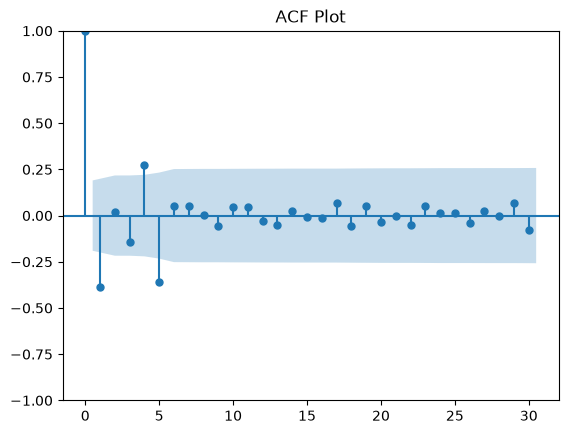

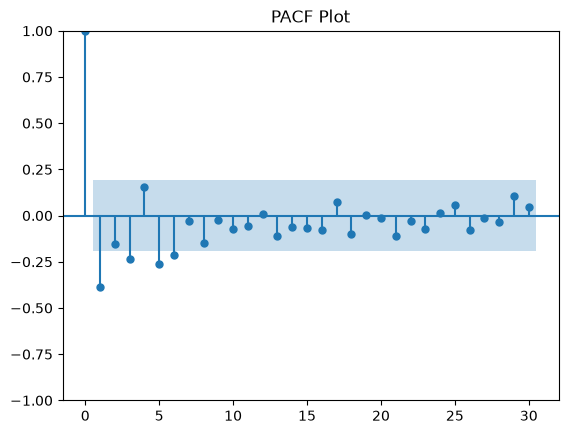

In [73]:
# from google.colab import drive
# drive.mount('/content/gdrive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt

#df = pd.read_csv('/content/gdrive/MyDrive/Tina AI study/Walmart_Sales.csv', encoding='latin1')

df = pd.read_csv('Walmart_Sales.csv', encoding='latin1')

df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

sales_mean = df.groupby('Store')['Weekly_Sales'].mean().reset_index()
#print(sales_mean)
sales_mean = sales_mean.sort_values(
    'Weekly_Sales',
    ascending=False
)
#print(sales_mean.head())
best_store = sales_mean.iloc[0]['Store']
#print(best_store)


best_store_df = df[df['Store'] == best_store].copy()

sales_by_date = best_store_df[['Date', 'Weekly_Sales']].copy()
sales_by_date = sales_by_date .sort_values('Date')

#print(sales_by_date.head())
#print(sales_by_date.tail())

arima = sales_by_date.set_index('Date')['Weekly_Sales']

split_ind = int(len(arima) * 0.75)

train = arima.iloc[:split_ind]
test = arima.iloc[split_ind:]

from statsmodels.tsa.arima.model import ARIMA

d = 1
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train)


if adf_result[1] <= 0.05:
    d = 0
else:
    d = 1
print(f"The value of d is: {d}")
arima_model = ARIMA(train, order=(2, 2, 2))

arima_result = arima_model.fit() # trained model
print(arima_result.summary())

forecast = arima_result.forecast(steps=len(test)) #forecasting
print("Forecast\n",forecast)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plot_acf(train.diff().dropna(), lags=30)
plt.title("ACF Plot")
plt.show()

plot_pacf(train.diff().dropna(), lags=30)
plt.title("PACF Plot")
plt.show()

**What this cell does:** applies first-order differencing (each week minus the week before) to remove the trend, and plots the result to check if it looks stationary (flat, around a constant mean).

Original data head:
 Date
2010-02-05    2401395.47
2010-02-12    2109107.90
2010-02-19    2161549.76
2010-02-26    1898193.95
2010-03-05    2119213.72
Name: Weekly_Sales, dtype: float64

Differenced data head:
 Date
2010-02-12   -292287.57
2010-02-19     52441.86
2010-02-26   -263355.81
2010-03-05    221019.77
2010-03-12   -108238.88
Name: Weekly_Sales, dtype: float64


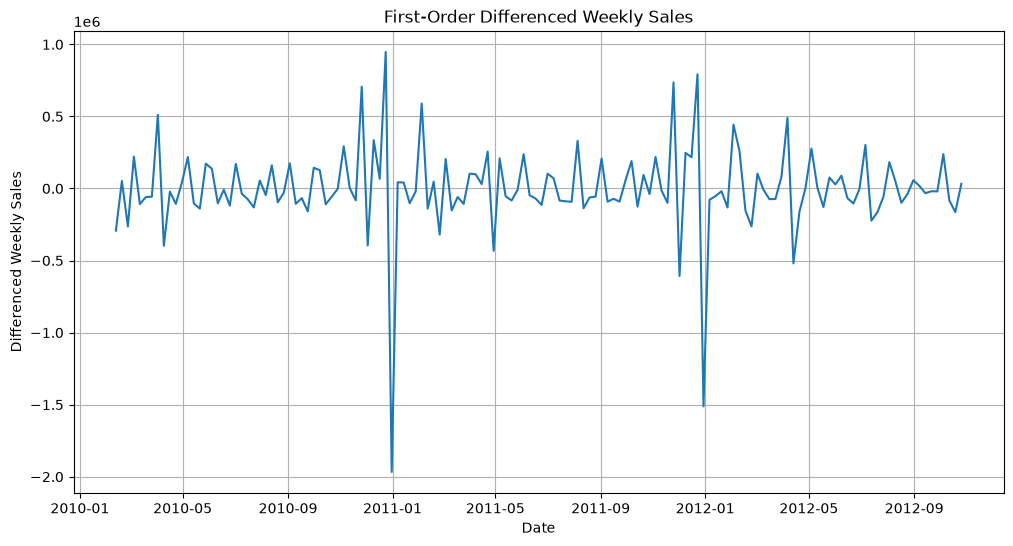

In [74]:
# Assuming 'arima' is your time series (e.g., from cell TAISJHU6X9fG)
# Perform first-order differencing
differenced_data = arima.diff().dropna()

print("Original data head:\n", arima.head())
print("\nDifferenced data head:\n", differenced_data.head())

# You can also plot the differenced data to visually inspect for stationarity
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(differenced_data)
plt.title('First-Order Differenced Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Differenced Weekly Sales')
plt.grid(True)
plt.show()

**What this cell does:** applies more differencing to see whether the series becomes more stationary. Note: the code applies `.diff()` seven times, although the comments call it second-order (which would be two times).

Original data head:
 Date
2010-02-05    2401395.47
2010-02-12    2109107.90
2010-02-19    2161549.76
2010-02-26    1898193.95
2010-03-05    2119213.72
Name: Weekly_Sales, dtype: float64

First-order differenced data head:
 Date
2010-02-12   -292287.57
2010-02-19     52441.86
2010-02-26   -263355.81
2010-03-05    221019.77
2010-03-12   -108238.88
Name: Weekly_Sales, dtype: float64

Second-order differenced data head:
 Date
2010-03-26   -10303601.50
2010-04-02     7079039.87
2010-04-09    -6348624.21
2010-04-16    11149032.64
2010-04-23   -16761944.57
Name: Weekly_Sales, dtype: float64


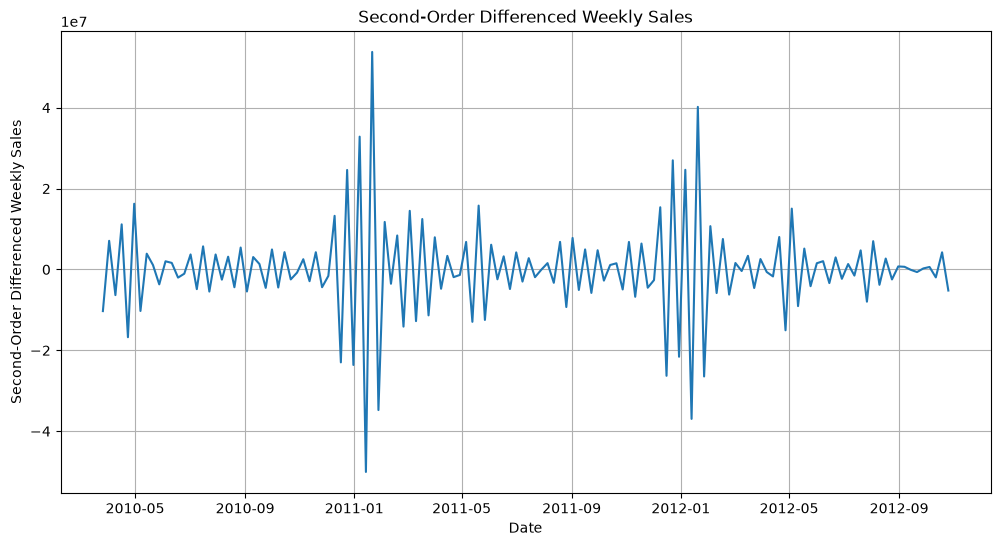

In [75]:
# Perform second-order differencing
# This means applying .diff() twice
second_order_differenced_data = arima.diff().diff().diff().diff().diff().diff().diff().dropna()

print("Original data head:\n", arima.head())
print("\nFirst-order differenced data head:\n", differenced_data.head())
print("\nSecond-order differenced data head:\n", second_order_differenced_data.head())

# Plot the second-order differenced data
plt.figure(figsize=(12, 6))
plt.plot(second_order_differenced_data)
plt.title('Second-Order Differenced Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Second-Order Differenced Weekly Sales')
plt.grid(True)
plt.show()

**What this cell does:** puts the actual test sales and the ARIMA forecast side by side in one table, then plots the training data, the test data and the forecast on one chart.

            Weekly_Sales
Date                    
2012-02-24    2045837.55
2012-03-02    2148822.76
2012-03-09    2139265.40
2012-03-16    2064991.71
2012-03-23    1992436.96
2012-03-30    2074721.74
2012-04-06    2565259.92
2012-04-13    2045396.06
2012-04-20    1884427.84
2012-04-27    1886503.93
2012-05-04    2163510.89
2012-05-11    2168097.11
2012-05-18    2039222.26
2012-05-25    2114989.00
2012-06-01    2143126.59
2012-06-08    2231962.13
2012-06-15    2165160.29
2012-06-22    2060588.69
2012-06-29    2055952.61
2012-07-06    2358055.30
2012-07-13    2134680.12
2012-07-20    1970170.29
2012-07-27    1911559.10
2012-08-03    2094515.71
2012-08-10    2144245.39
2012-08-17    2045061.22
2012-08-24    2005341.43
2012-08-31    2062481.56
2012-09-07    2080529.06
2012-09-14    2047949.98
2012-09-21    2028587.24
2012-09-28    2008350.58
2012-10-05    2246411.89
2012-10-12    2162951.36
2012-10-19    1999363.49
2012-10-26    2031650.55
                Actual     Predicted
Date         

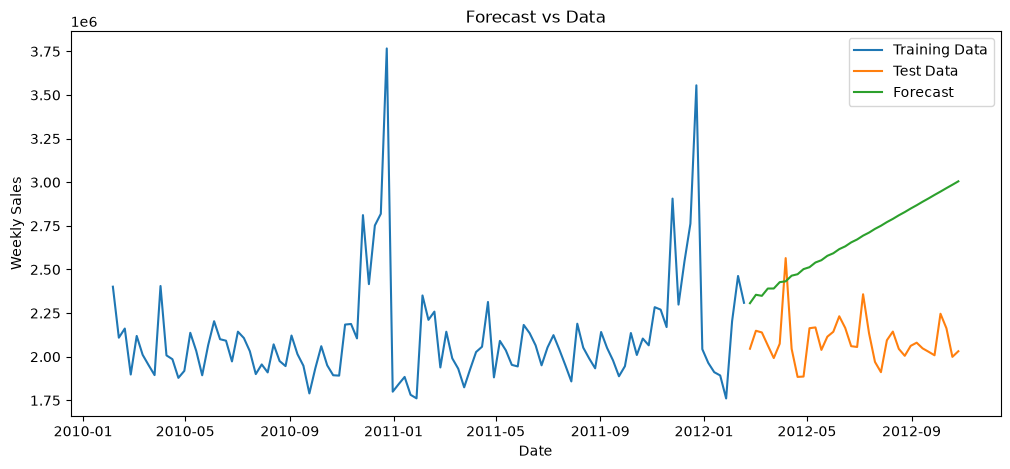

In [76]:
results = test.to_frame()
print(results)
# results.columnd = 'Actual'
results.columns = ['Actual']
results['Predicted'] = forecast.values

print(results.head())

plt.figure(figsize=(12,5))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Test Data')
plt.plot(results.index, results['Predicted'], label='Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('Forecast vs Data')
plt.legend()
plt.show()

**What this cell does:** measures ARIMA's accuracy with MAPE: for each test week it calculates how far the forecast is from the actual sales in %, then takes the average.

In [77]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
eval_df = test.to_frame()
eval_df.columns = ['actual']
eval_df['prediction'] = forecast.values
eval_df['forecast_error'] = eval_df['actual'] - eval_df['prediction']

eval_df['absolute_percentage_error'] = (
    eval_df['forecast_error'].abs() / eval_df['actual']
) * 100

arima_mape = eval_df['absolute_percentage_error'].mean()

print("MAPE:", arima_mape)

MAPE: 28.0562817910497


##random Forest

**What this cell does:** builds and evaluates a Random Forest for the best store.
1. Loads the data and runs the ADF stationarity test on the sales of all stores.
2. Keeps only the best store (Store 20), sorted by date.
3. Adds features: calendar features (`year`, `month`, `week`) and lag features (sales 1, 2, 3 and 4 weeks ago).
4. Prints how strongly each feature is correlated with `Weekly_Sales`.
5. Removes the first rows, which have no lag values, then splits by time (75% train / 25% test).
6. Trains a Random Forest with 100 trees, predicts the test weeks, prints the MAPE and plots the forecast.

p-value: 0.000117
20.0
Corr Matrix:-  Weekly_Sales    1.000000
lag_1           0.381550
month           0.355361
week            0.337603
lag_2           0.223447
lag_4           0.154124
Holiday_Flag    0.140983
lag_3           0.090290
Date            0.071747
CPI             0.058706
Fuel_Price     -0.013507
year           -0.043628
Unemployment   -0.095341
Temperature    -0.264983
Name: Weekly_Sales, dtype: float64
MAPE: 3.8273651472926016


/var/folders/b3/2tbk3zy55bb28myr00ztdbw00000gp/T/ipykernel_30701/1252575221.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['Weekly_Sales'].dropna())


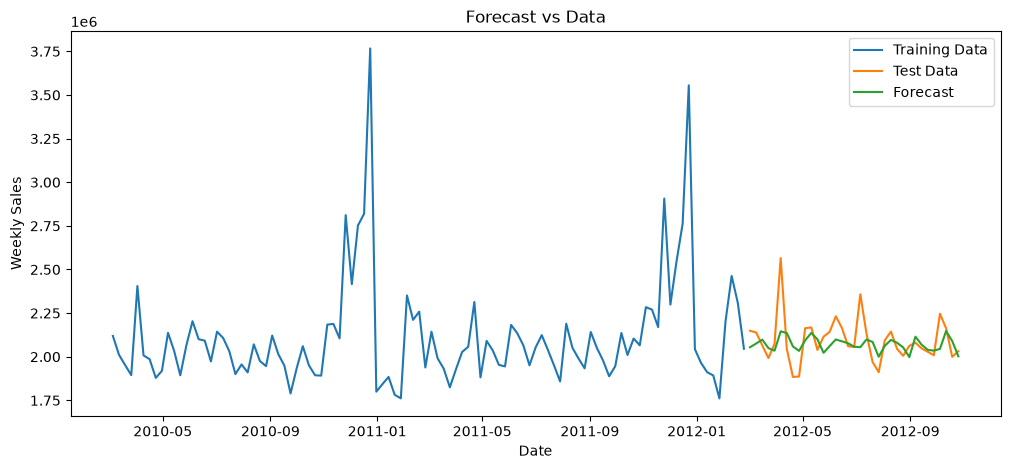

In [78]:
#from google.colab import drive
#drive.mount('/content/gdrive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv('Walmart_Sales.csv', encoding='latin1')
# make it date, not test format; format is mixed, needs custom
df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)
df.head()
from statsmodels.tsa.stattools import adfuller
from numpy import log
result = adfuller(df['Weekly_Sales'].dropna())
print('p-value: %f' % result[1]) #check if data is stationary


store_sales = df.groupby('Store')['Weekly_Sales'].mean().reset_index()
store_sales = store_sales.sort_values(
    'Weekly_Sales',
    ascending=False
)

best_store = store_sales.iloc[0]['Store']
print(best_store)
# print(store_sales.head())

best_store_df = df[df['Store'] == best_store].copy()

best_store_df = best_store_df.sort_values('Date')

# print(best_store_df.head())

rf_df = best_store_df[['Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                       'Fuel_Price', 'CPI', 'Unemployment']].copy()

rf_df = rf_df.sort_values('Date')

# print(rf_df)

# print(rf_df.dtypes)
# Seasonal variable
rf_df['year'] = rf_df['Date'].dt.year
rf_df['month'] = rf_df['Date'].dt.month
rf_df['week'] = rf_df['Date'].dt.isocalendar().week.astype(int)

# weekly sales
rf_df['lag_1'] = rf_df['Weekly_Sales'].shift(1) # last wee
rf_df['lag_2'] = rf_df['Weekly_Sales'].shift(2) # 2 weeks ago
rf_df['lag_3'] = rf_df['Weekly_Sales'].shift(3) # 3 weeks ago - ADDED THIS LINE
rf_df['lag_4'] = rf_df['Weekly_Sales'].shift(4) # a month ago

##correlation on the features
corr_matrix = rf_df.corr()
print("Corr Matrix:- ",corr_matrix['Weekly_Sales'].sort_values(ascending=False))

rf_df = rf_df.dropna() #removing missing values, getting new rf_df

# print(rf_df.head())

split_ind = int(len(rf_df) * 0.75)

train_rf = rf_df.iloc[:split_ind]
test_rf = rf_df.iloc[split_ind:]

features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_3', 'lag_4']

x_train = train_rf[features]
y_train = train_rf['Weekly_Sales']

x_test = test_rf[features]
y_test = test_rf['Weekly_Sales']

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)

y_pred = rf_model.predict(x_test)

# Estimate MAPE
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
print("MAPE:", mape)


# plot RF
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(train_rf['Date'], train_rf['Weekly_Sales'], label='Training Data')
plt.plot(test_rf['Date'], test_rf['Weekly_Sales'], label='Test Data')
plt.plot(test_rf['Date'], y_pred, label='Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title('Forecast vs Data')
plt.legend()
plt.show()

### Random forest 10 best stores

**What this cell does:** trains one Random Forest on the 10 best stores together.
1. Selects the 10 stores with the highest average sales.
2. Adds the same calendar and lag features, calculating lags separately for each store so sales from different stores don't mix.
3. Splits by date, so every store has the same training weeks and test weeks.
4. Uses `Store` as an extra feature, so one model learns all 10 stores.
5. Plots the training data, test data and forecast for each store.

2012-03-02 00:00:00
[ 1  2  4  6 10 13 14 20 27 39]


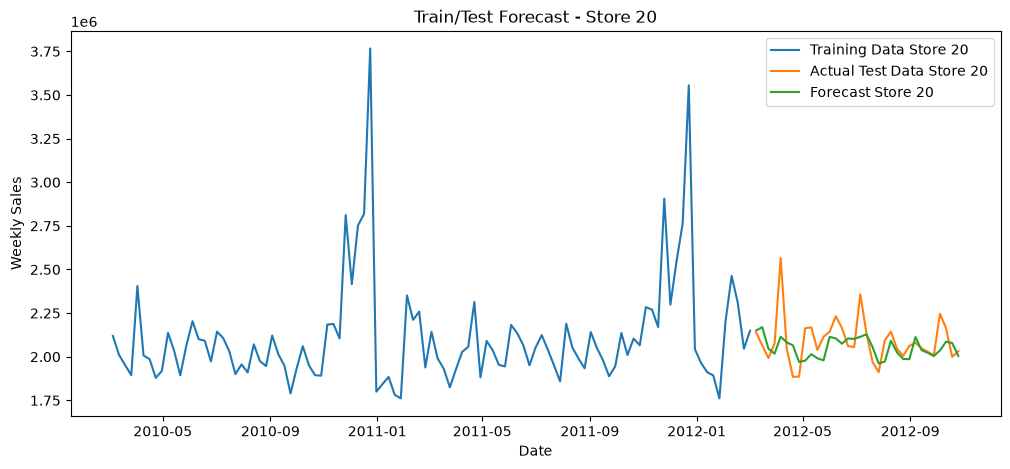

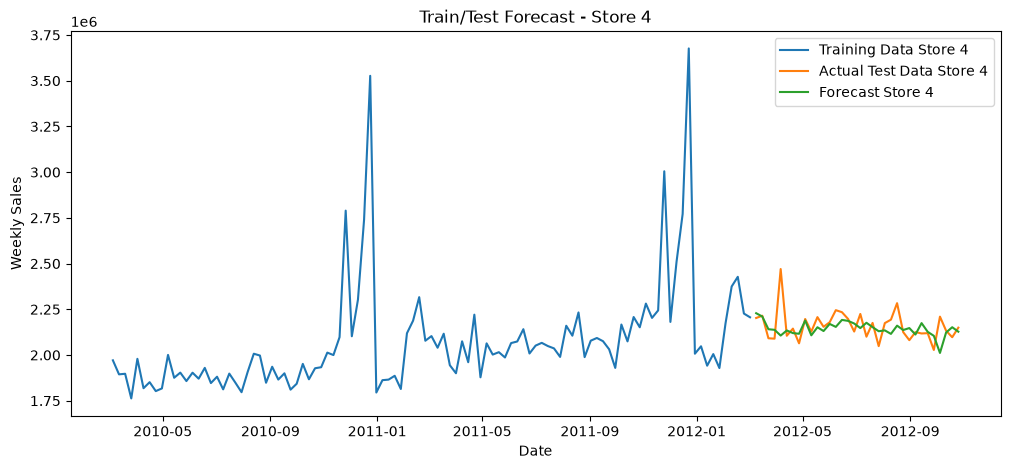

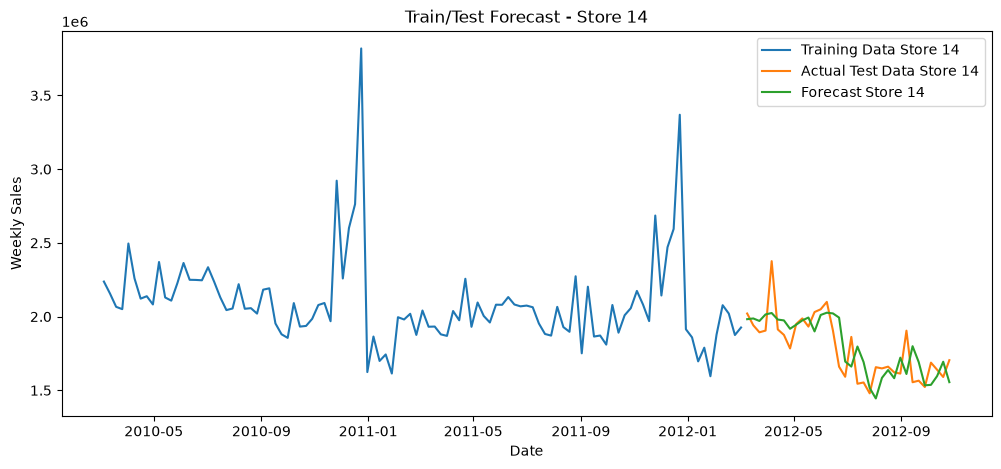

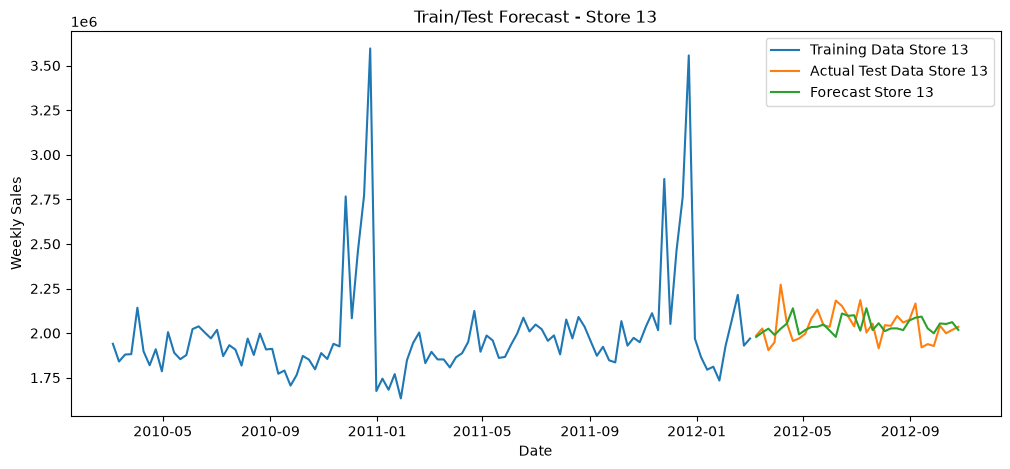

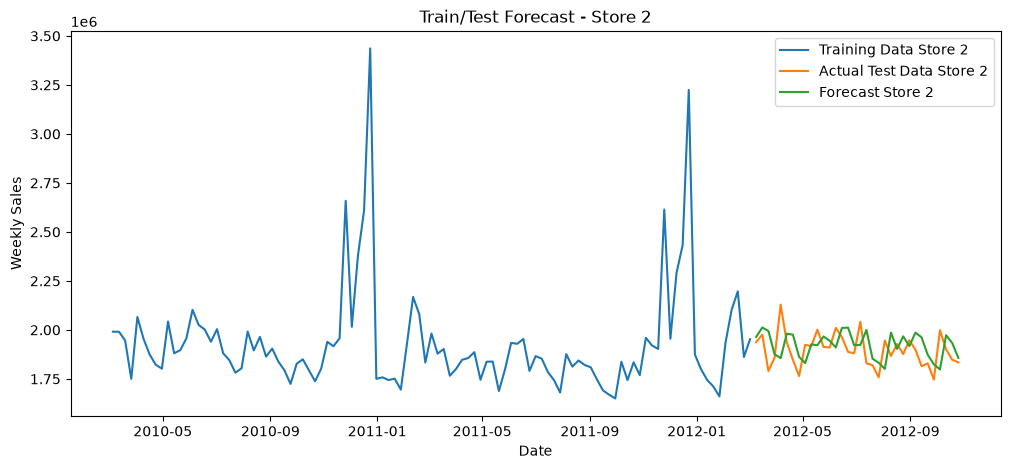

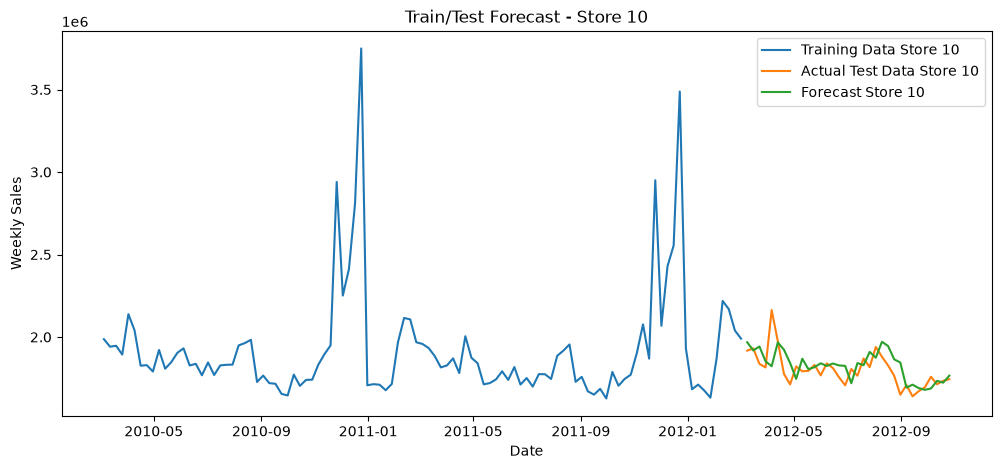

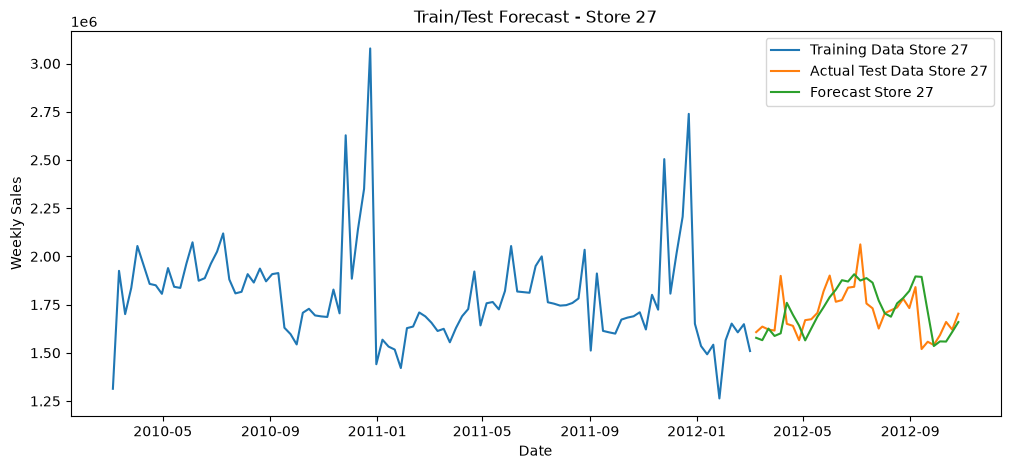

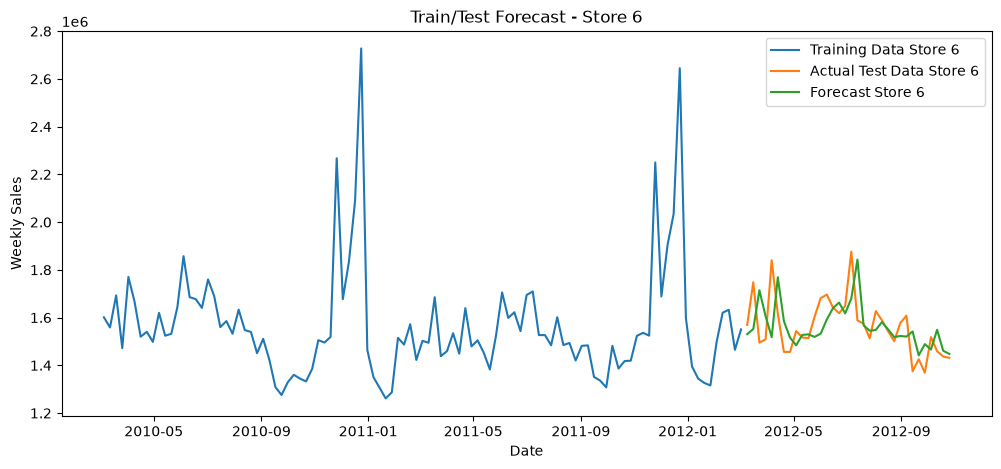

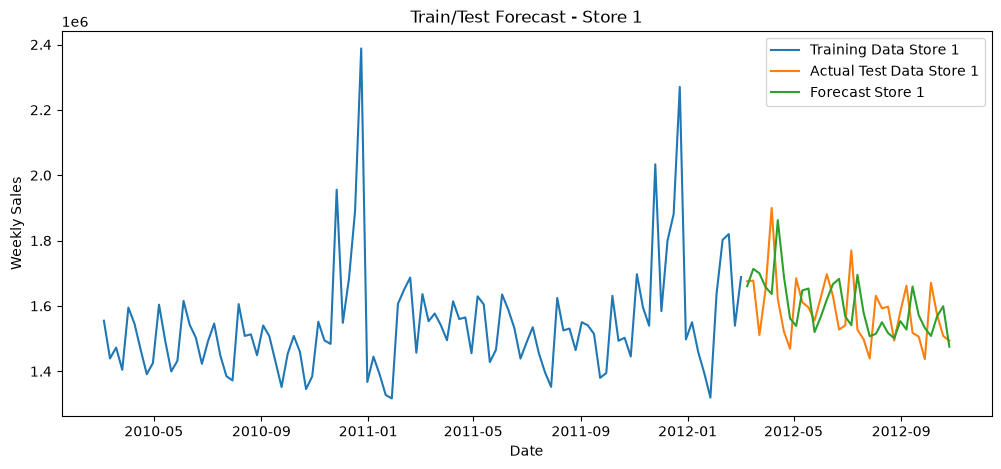

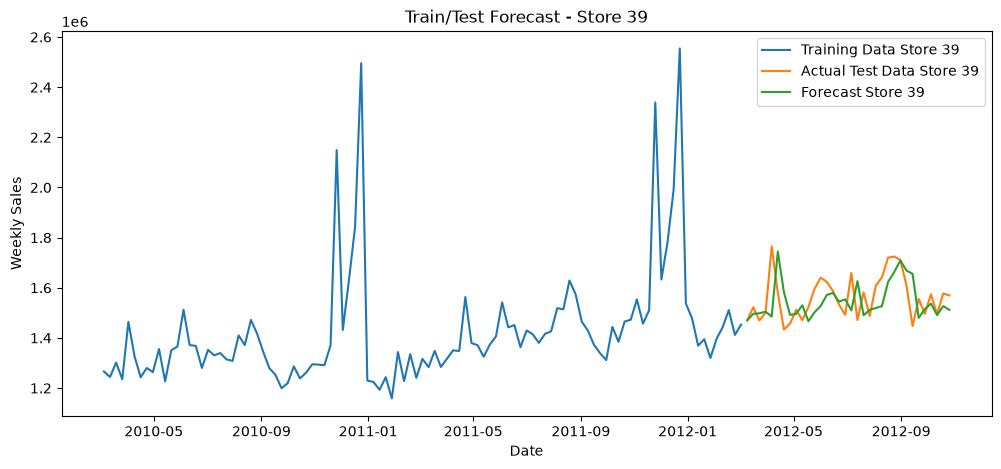

In [79]:
#from google.colab import drive
#drive.mount('/content/gdrive', force_remount=True)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv('Walmart_Sales.csv', encoding='latin1')
# make it date, not test format; format is mixed, needs custom
df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)
df.head()
from numpy import log


store_sales = df.groupby('Store')['Weekly_Sales'].mean().reset_index()
store_sales = store_sales.sort_values(
    'Weekly_Sales',
    ascending=False
)

top_10_stores = store_sales.head(10)['Store'].tolist() # add top 10 stores to the list, they all were already listed in the table, i just take 10 top stores.
# print(f"Top 10 Stores: {top_10_stores}")

# Filter the original DataFrame to include only the top 10 stores
rf_df = df[df['Store'].isin(top_10_stores)].copy()

# Sort by Store and Date to ensure correct lag calculations within each store
rf_df = rf_df.sort_values(by=['Store', 'Date'])
#print(rf_df.head())

# print(best_store_df.head())

rf_df = rf_df[['Date', 'Store', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                       'Fuel_Price', 'CPI', 'Unemployment']].copy()

# print(rf_df)

# print(rf_df.dtypes)
# Seasonal variable
rf_df['year'] = rf_df['Date'].dt.year
rf_df['month'] = rf_df['Date'].dt.month
rf_df['week'] = rf_df['Date'].dt.isocalendar().week.astype(int)

# weekly sales - Apply shift grouped by Store
rf_df['lag_1'] = rf_df.groupby('Store')['Weekly_Sales'].shift(1)
rf_df['lag_2'] = rf_df.groupby('Store')['Weekly_Sales'].shift(2)
rf_df['lag_3'] = rf_df.groupby('Store')['Weekly_Sales'].shift(3)
rf_df['lag_4'] = rf_df.groupby('Store')['Weekly_Sales'].shift(4)

##correlation on the features
corr_matrix = rf_df.corr()
#print("Corr Matrix:-\n",corr_matrix['Weekly_Sales'].sort_values(ascending=False))

rf_df = rf_df.dropna() #removing missing values, getting new rf_df

## Split by index doesn't work. It creates inconsistency in splitting the data, giving only 3 stores to work with which leads to the lack of stores to display in the plots.
## Not sure if im doing the right thing
## Instead, I will try splitting it by date
unique_dates = sorted(rf_df['Date'].unique())
split_date = unique_dates[int(len(unique_dates) * 0.75)]
print(split_date)


train_rf = rf_df[rf_df['Date']<=split_date]
test_rf = rf_df[rf_df['Date']>split_date]

# print("Stores in train:", sorted(train_rf['Store'].unique()))
# print("Stores in test:", sorted(test_rf['Store'].unique()))

features = ['Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_3', 'lag_4']

x_train = train_rf[features]
y_train = train_rf['Weekly_Sales']

x_test = test_rf[features]
y_test = test_rf['Weekly_Sales']

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train) #training
y_pred = rf_model.predict(x_test) #making a prediction after training.

# Estimate MAPE
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
#print("MAPE:", mape)


# plot RF
import matplotlib.pyplot as plt

print(test_rf['Store'].unique())

for store_to_plot in top_10_stores:


  train_rf_store = train_rf[train_rf['Store'] == store_to_plot].copy()
  test_rf_store = test_rf[test_rf['Store'] == store_to_plot].copy()

  x_test_store = test_rf_store[features]
  y_pred_store = rf_model.predict(x_test_store)

  plt.figure(figsize=(12, 5))

  plt.plot(
    train_rf_store['Date'],
    train_rf_store['Weekly_Sales'],
    label=f'Training Data Store {store_to_plot}'
  )

  plt.plot(
    test_rf_store['Date'],
    test_rf_store['Weekly_Sales'],
    label=f'Actual Test Data Store {store_to_plot}'
  )

  plt.plot(
    test_rf_store['Date'],
    y_pred_store,
    label=f'Forecast Store {store_to_plot}'
  )

  plt.xlabel('Date')
  plt.ylabel('Weekly Sales')
  plt.title(f'Train/Test Forecast - Store {store_to_plot}')
  plt.legend()
  plt.show()

**What this cell does:** prints the date ranges of the full data, the training data and the test data, to confirm the split is by time (all test weeks come after the training weeks).

In [80]:
print("Full data date range:")
print(rf_df['Date'].min(), "to", rf_df['Date'].max())

print("\nTraining date range:")
print(train_rf['Date'].min(), "to", train_rf['Date'].max())

print("\nTesting date range:")
print(test_rf['Date'].min(), "to", test_rf['Date'].max())

Full data date range:
2010-03-05 00:00:00 to 2012-10-26 00:00:00

Training date range:
2010-03-05 00:00:00 to 2012-03-02 00:00:00

Testing date range:
2012-03-09 00:00:00 to 2012-10-26 00:00:00


**What this cell does:** plots only Store 20 from the 10-store model, to compare it with the single-store Random Forest above.

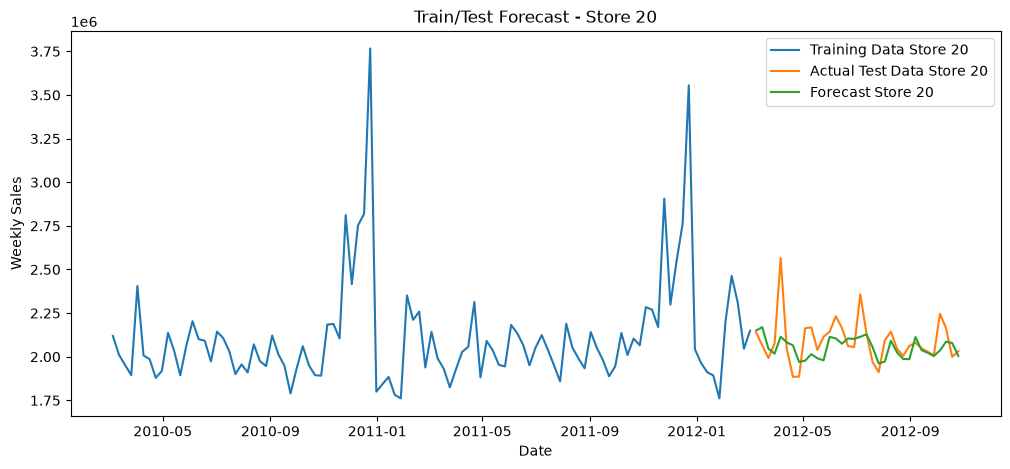

In [81]:
store_to_plot = 20

train_rf_store = train_rf[train_rf['Store'] == store_to_plot].copy()
test_rf_store = test_rf[test_rf['Store'] == store_to_plot].copy()

x_test_store = test_rf_store[features]
y_pred_store = rf_model.predict(x_test_store)

plt.figure(figsize=(12, 5))

plt.plot(
    train_rf_store['Date'],
    train_rf_store['Weekly_Sales'],
    label=f'Training Data Store {store_to_plot}'
)

plt.plot(
    test_rf_store['Date'],
    test_rf_store['Weekly_Sales'],
    label=f'Actual Test Data Store {store_to_plot}'
)

plt.plot(
    test_rf_store['Date'],
    y_pred_store,
    label=f'Forecast Store {store_to_plot}'
)

plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Train/Test Forecast - Store {store_to_plot}')
plt.legend()
plt.show()

### Perform KNN outlier Imputation

**What this cell does:** cleans outliers with KNN imputation, for Store 20 only.
1. Rebuilds the Store 20 table with the same features as the first Random Forest cell (the cell above replaced `rf_df` with 10 stores).
2. Splits by time **before** cleaning, so the test weeks stay unchanged and the model is tested on real data.
3. Looks for outliers only in `Temperature`, `Fuel_Price`, `CPI` and `Unemployment`, using the IQR rule (values far outside the middle 50% of the training data). `Weekly_Sales` is not cleaned, because its highest values are real holiday sales.
4. Replaces each outlier with a value based on the 5 most similar weeks (KNN imputation).
5. Plots each feature that changed, before and after cleaning.

Outliers marked in the training data:
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    4
dtype: int64

Missing values after KNN imputation (should be 0):
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64


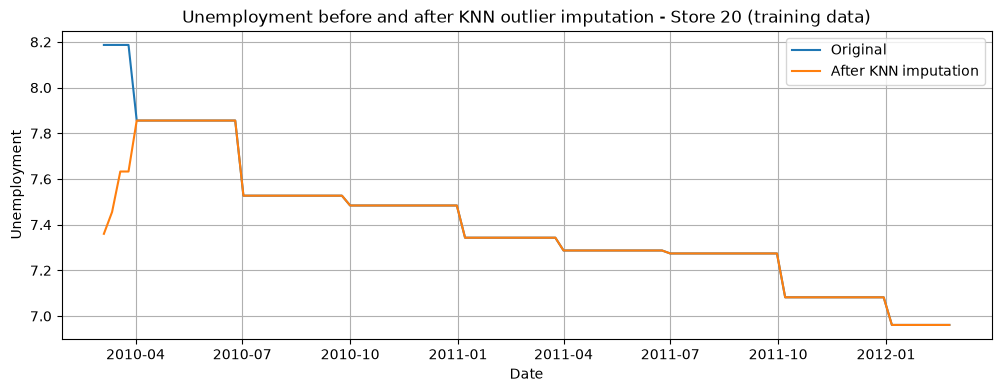

In [82]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer
import matplotlib.pyplot as plt

# rf_df was overwritten by the "10 best stores" cell above, so it now contains 10 stores.
# Rebuild the table for the best store only (Store 20), the same way as in the first Random Forest cell.
# rf_df_cleaned = rf_df.copy()
rf_df_store = best_store_df[['Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                             'Fuel_Price', 'CPI', 'Unemployment']].copy()
rf_df_store = rf_df_store.sort_values('Date')

# Seasonal variables
rf_df_store['year'] = rf_df_store['Date'].dt.year
rf_df_store['month'] = rf_df_store['Date'].dt.month
rf_df_store['week'] = rf_df_store['Date'].dt.isocalendar().week.astype(int)

# Lag features: sales 1, 2, 3 and 4 weeks ago
rf_df_store['lag_1'] = rf_df_store['Weekly_Sales'].shift(1)
rf_df_store['lag_2'] = rf_df_store['Weekly_Sales'].shift(2)
rf_df_store['lag_3'] = rf_df_store['Weekly_Sales'].shift(3)
rf_df_store['lag_4'] = rf_df_store['Weekly_Sales'].shift(4)
rf_df_store = rf_df_store.dropna()

# Split by time BEFORE cleaning: first 75% of weeks = training, last 25% = test.
# The test weeks are left exactly as they are, because they stand for real future data.
split_ind = int(len(rf_df_store) * 0.75)
train_knn = rf_df_store.iloc[:split_ind].copy()
test_knn = rf_df_store.iloc[split_ind:].copy()
train_knn_before = train_knn.copy()  # kept to compare before/after in the plot

# Only the economic/weather features are checked for outliers.
# Weekly_Sales and the lags are NOT changed: their very high values are real holiday sales.
# numerical_cols = rf_df_cleaned.select_dtypes(include=np.number).columns.tolist()
outlier_cols = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

# Step 1: mark outliers as NaN with the IQR rule, using the training data only
for col in outlier_cols:
    Q1 = train_knn[col].quantile(0.25)
    Q3 = train_knn[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    train_knn[col] = np.where(
        (train_knn[col] < lower_bound) | (train_knn[col] > upper_bound),
        np.nan,
        train_knn[col]
    )

print("Outliers marked in the training data:")
print(train_knn[outlier_cols].isnull().sum())

# Step 2: replace the marked values with KNN imputation (fitted on the training data only)
imputer = KNNImputer(n_neighbors=5)
train_knn[outlier_cols] = imputer.fit_transform(train_knn[outlier_cols])

print("\nMissing values after KNN imputation (should be 0):")
print(train_knn[outlier_cols].isnull().sum())

# Plot each feature that changed: original vs imputed
changed_cols = [col for col in outlier_cols if not train_knn[col].equals(train_knn_before[col])]
for col in changed_cols:
    plt.figure(figsize=(12, 4))
    plt.plot(train_knn_before['Date'], train_knn_before[col], label='Original')
    plt.plot(train_knn['Date'], train_knn[col], label='After KNN imputation')
    plt.title(f'{col} before and after KNN outlier imputation - Store {int(best_store)} (training data)')
    plt.xlabel('Date')
    plt.ylabel(col)
    plt.legend()
    plt.grid(True)
    plt.show()

### K-Fold Cross-Validation for Random Forest

**What this cell does:** tunes the Random Forest with time-series cross-validation.
1. Uses the KNN-cleaned Store 20 training weeks only.
2. `TimeSeriesSplit` cuts them into 5 folds where each validation period comes after its training period, the way real forecasting works.
3. Tries 18 combinations of `n_estimators`, `max_depth` and `min_samples_split`, and keeps the one with the lowest average MAPE in `best_params_rf`.

In [83]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, ParameterGrid
import numpy as np
from sklearn.ensemble import RandomForestRegressor

## train_knn is the KNN outlier imputation strategy (Store 20, training weeks only)
# rf_df = rf_df_cleaned.copy()
features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_4']
# Combine features and target for cross-validation
# Only the training weeks are used, so the test weeks are never seen while tuning
# X = rf_df[features]
# y = rf_df['Weekly_Sales']
X = train_knn[features]
y = train_knn['Weekly_Sales']

# Define the K-fold splitter using TimeSeriesSplit
# n_splits determines the number of train/test splits.
# For example, with 5 splits, it will create 5 different train/test sets,
# where each test set comes after its corresponding training set.
kf = TimeSeriesSplit(n_splits=5)

# Define a custom scoring function for MAPE
def mape_scorer(estimator, X, y_true):
    y_pred = estimator.predict(X)
    # Ensure y_true does not contain zero to avoid division by zero
    y_true_safe = np.where(y_true == 0, 1e-10, y_true) # Replace zeros with a very small number
    return -np.mean(np.abs((y_true - y_pred) / y_true_safe)) * 100

# Define a grid of hyperparameters to search for RandomForestRegressor
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

all_params_rf = list(ParameterGrid(param_grid_rf))

mapes_rf = [] # To store the MAPE for each parameter combination

print(f'Total Random Forest models to evaluate: {len(all_params_rf)}')

# Iterate over each parameter combination
for i, params_rf in enumerate(all_params_rf):
    #print(f'Evaluating Random Forest model {i+1}/{len(all_params_rf)} with params: {params_rf}')

    # Create and fit a RandomForestRegressor model with the current parameters
    rf_model_tune = RandomForestRegressor(random_state=42, **params_rf)

    # Perform cross-validation and get MAPE scores
    # We'll use the negative MAPE from the scorer, so we need to negate it back for true MAPE
    cv_scores = cross_val_score(rf_model_tune, X, y, cv=kf, scoring=mape_scorer)
    print(cv_scores)
    # The scorer returns negative MAPE, so we take the mean of the negated scores
    mean_mape = -cv_scores.mean()

    mapes_rf.append(mean_mape)

# Find the best parameters based on the lowest MAPE
best_params_idx_rf = mapes_rf.index(min(mapes_rf))
best_params_rf = all_params_rf[best_params_idx_rf]

# print(f'\nBest Random Forest parameters found: {best_params_rf}')
# print(f'Lowest Mean MAPE achieved: {min(mapes_rf):.4f}')

# Retrain the final model using these best parameters on the full training data
final_rf_model = RandomForestRegressor(random_state=42, **best_params_rf)
final_rf_model.fit(X, y) # Fit on the training data (X, y)

# print('\nFinal Random Forest model trained with best parameters!')


Total Random Forest models to evaluate: 18
[ -6.54084393 -16.39278438  -5.64122491  -3.31677608  -7.94972559]
[ -6.90391503 -16.24088851  -5.56303482  -3.49229685  -8.20544981]
[ -6.75485818 -16.21492773  -5.8131287   -3.35256822  -8.03326033]
[ -6.33341342 -16.32520141  -5.77968396  -3.24090237  -9.29121662]
[ -6.79103173 -16.18569571  -5.85996006  -3.39444599  -9.18201731]
[ -6.59867648 -16.197391    -5.96785296  -3.36799061  -8.93897663]
[ -6.54084393 -16.39278438  -5.75521222  -3.19857686  -7.87709064]
[ -6.90391503 -16.24325422  -5.64596489  -3.35861718  -7.98904057]
[ -6.75485818 -16.22187515  -5.81134805  -3.28439492  -8.01400787]
[ -6.33341342 -16.32520141  -5.78054027  -3.2109501   -9.21666288]
[ -6.79103173 -16.18569571  -5.86041651  -3.38618168  -9.20170612]
[ -6.59867648 -16.197391    -5.976702    -3.35325654  -9.02574673]
[ -6.54084393 -16.39278438  -5.64122491  -3.31677608  -7.94972559]
[ -6.90391503 -16.24088851  -5.56303482  -3.49229685  -8.20544981]
[ -6.75485818 -16.2

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

**What this cell does:** trains a Random Forest with the best parameters found above on the KNN-cleaned training weeks, then tests it on the real test weeks. It prints the MAPE and plots the training data, test data and forecast.

MAPE: 3.596796313633386


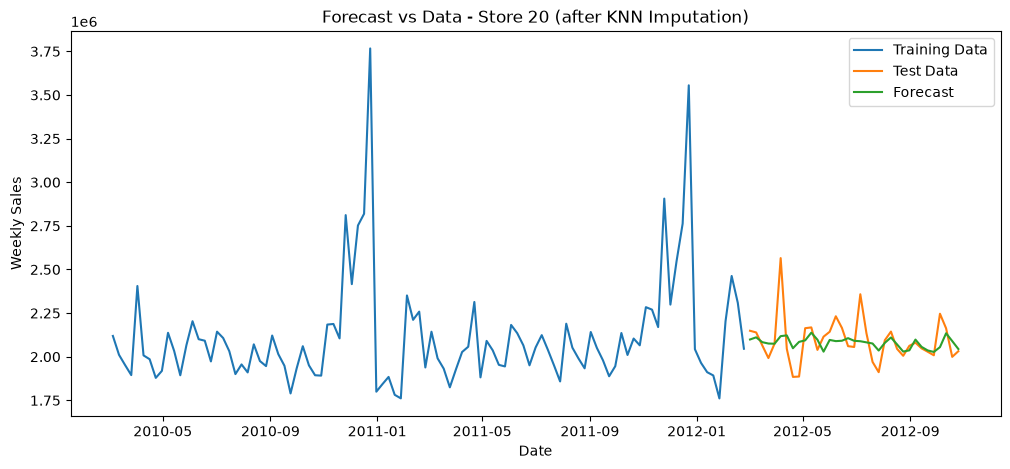

In [84]:
### Using the best params from kfold to fit the randomforest,
from sklearn.ensemble import RandomForestRegressor

# Use the Store 20 split from the KNN imputation cell:
# cleaned training weeks, and the real (unchanged) test weeks

# Ensure features list is consistent
features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_4']

# split_ind = int(len(rf_df) * 0.75)
#
# train_rf_cleaned = rf_df.iloc[:split_ind]
# test_rf_cleaned = rf_df.iloc[split_ind:]
train_rf_cleaned = train_knn
test_rf_cleaned = test_knn

x_train = train_rf_cleaned[features]
y_train = train_rf_cleaned['Weekly_Sales']

x_test = test_rf_cleaned[features]
y_test = test_rf_cleaned['Weekly_Sales']

# Use the best_params_rf found during cross-validation
# The best_params_rf dictionary was determined in the K-Fold cell above
# We will instantiate the RandomForestRegressor with these optimal parameters
rf_model = RandomForestRegressor(random_state=42, **best_params_rf)
rf_model.fit(x_train, y_train)

# Make predictions on the test set using the tuned model
y_pred = rf_model.predict(x_test)
# Estimate MAPE
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
print("MAPE:", mape)


# plot RF
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(train_rf_cleaned['Date'], train_rf_cleaned['Weekly_Sales'], label='Training Data') # Use cleaned train data for plot
plt.plot(test_rf_cleaned['Date'], test_rf_cleaned['Weekly_Sales'], label='Test Data')     # Use cleaned test data for plot
plt.plot(test_rf_cleaned['Date'], y_pred, label='Forecast')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Forecast vs Data - Store {int(best_store)} (after KNN Imputation)')
plt.legend()
plt.show()

### Median Outlier Imputation

**What this cell does:** rebuilds the Store 20 table from the original data (before any cleaning), with the same calendar and lag features, so the median imputation starts from the same data as the KNN imputation.

In [85]:
import pandas as pd
import numpy as np


# NOTE: this uses best_store_df (Store 20) from the first Random Forest cell, so run that cell first.

rf_df_original = best_store_df[['Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
                       'Fuel_Price', 'CPI', 'Unemployment']].copy()

rf_df_original = rf_df_original.sort_values('Date')

# Seasonal variable
rf_df_original['year'] = rf_df_original['Date'].dt.year
rf_df_original['month'] = rf_df_original['Date'].dt.month
rf_df_original['week'] = rf_df_original['Date'].dt.isocalendar().week.astype(int)

# weekly sales
rf_df_original['lag_1'] = rf_df_original['Weekly_Sales'].shift(1)
rf_df_original['lag_2'] = rf_df_original['Weekly_Sales'].shift(2)
rf_df_original['lag_3'] = rf_df_original['Weekly_Sales'].shift(3)
rf_df_original['lag_4'] = rf_df_original['Weekly_Sales'].shift(4)

# Drop initial NaNs created by shift operations
rf_df_original = rf_df_original.dropna().copy()

print("Head of re-created rf_df_original:")
display(rf_df_original.head())
print("Number of NaNs in re-created rf_df_original:")
print(rf_df_original.isnull().sum())

Head of re-created rf_df_original:


,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,year,month,week,lag_1,lag_2,lag_3,lag_4
2721,2010-03-05,2119213.72,0,31.75,2.777,204.494073,8.187,2010,3,9,1898193.95,2161549.76,2109107.90,2401395.47
2722,2010-03-12,2010974.84,0,43.82,2.818,204.525060,8.187,2010,3,10,2119213.72,1898193.95,2161549.76,2109107.90
2723,2010-03-19,1951848.43,0,47.32,2.844,204.378226,8.187,2010,3,11,2010974.84,2119213.72,1898193.95,2161549.76
2724,2010-03-26,1894742.95,0,50.49,2.854,204.201755,8.187,2010,3,12,1951848.43,2010974.84,2119213.72,1898193.95
2725,2010-04-02,2405395.22,0,51.00,2.850,204.025284,7.856,2010,4,13,1894742.95,1951848.43,2010974.84,2119213.72


Number of NaNs in re-created rf_df_original:
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
year            0
month           0
week            0
lag_1           0
lag_2           0
lag_3           0
lag_4           0
dtype: int64


**What this cell does:** cleans outliers with median imputation, the same way as the KNN cell but with a simpler rule.
1. Splits by time **before** cleaning, so the test weeks stay unchanged.
2. Looks for outliers only in `Temperature`, `Fuel_Price`, `CPI` and `Unemployment` with the IQR rule. `Weekly_Sales` is not cleaned, because its highest values are real holiday sales.
3. Replaces each outlier with that column's median in the training data.
4. Plots each feature that changed, before and after cleaning.

Outliers marked in the training data:
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    4
dtype: int64

Missing values after Median imputation (should be 0):
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64


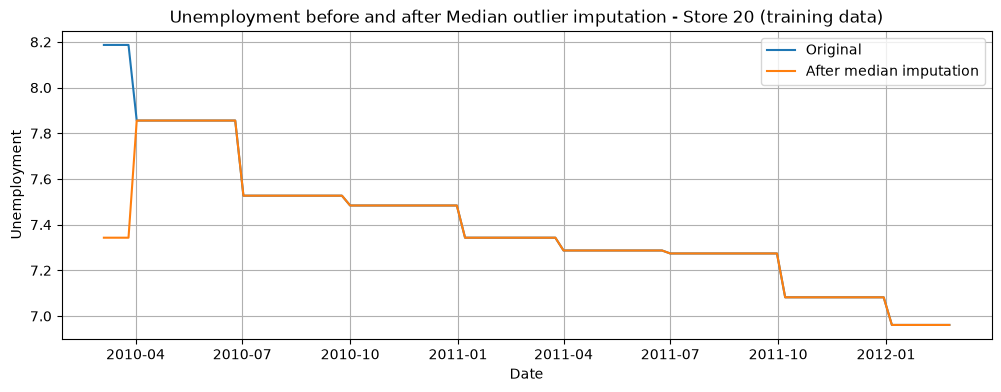

In [86]:
from sklearn.impute import SimpleImputer # used for mean, mode, median imputation
import matplotlib.pyplot as plt

# Split by time BEFORE cleaning: first 75% of weeks = training, last 25% = test.
# The test weeks are left exactly as they are, because they stand for real future data.
# rf_df_median_imputed = rf_df_original.copy()
split_ind_median = int(len(rf_df_original) * 0.75)
train_median = rf_df_original.iloc[:split_ind_median].copy()
test_median = rf_df_original.iloc[split_ind_median:].copy()
train_median_before = train_median.copy()  # kept to compare before/after in the plot

# Only the economic/weather features are checked for outliers.
# Weekly_Sales and the lags are NOT changed: their very high values are real holiday sales.
# numerical_cols = rf_df_median_imputed.select_dtypes(include=np.number).columns.tolist()
outlier_cols = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

# Step 1: mark outliers as NaN with the IQR rule, using the training data only
for col in outlier_cols:
    Q1 = train_median[col].quantile(0.25)
    Q3 = train_median[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    train_median[col] = np.where(
        (train_median[col] < lower_bound) | (train_median[col] > upper_bound),
        np.nan,
        train_median[col]
    )

print("Outliers marked in the training data:")
print(train_median[outlier_cols].isnull().sum())

# Step 2: replace the marked values with the median of the training data
imputer_median = SimpleImputer(strategy='median')
train_median[outlier_cols] = imputer_median.fit_transform(train_median[outlier_cols])

print("\nMissing values after Median imputation (should be 0):")
print(train_median[outlier_cols].isnull().sum())

# Plot each feature that changed: original vs imputed
changed_cols = [col for col in outlier_cols if not train_median[col].equals(train_median_before[col])]
for col in changed_cols:
    plt.figure(figsize=(12, 4))
    plt.plot(train_median_before['Date'], train_median_before[col], label='Original')
    plt.plot(train_median['Date'], train_median[col], label='After median imputation')
    plt.title(f'{col} before and after Median outlier imputation - Store {int(best_store)} (training data)')
    plt.xlabel('Date')
    plt.ylabel(col)
    plt.legend()
    plt.grid(True)
    plt.show()

**What this cell does:** tunes the Random Forest on the median-cleaned training weeks, with the same time-series cross-validation and the same 18 parameter combinations as for KNN, and trains the final model with the best ones.

In [87]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, ParameterGrid

# Use the median-imputed training weeks for tuning, so the test weeks are never seen
# rf_df_current = rf_df_median_imputed.copy()

features = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'year', 'month', 'week', 'lag_1', 'lag_2', 'lag_4']

# X_median = rf_df_current[features]
# y_median = rf_df_current['Weekly_Sales']
X_median = train_median[features]
y_median = train_median['Weekly_Sales']

# Define the K-fold splitter using TimeSeriesSplit
kf_median = TimeSeriesSplit(n_splits=5)

# Define a custom scoring function for MAPE
def mape_scorer(estimator, X, y_true):
    y_pred = estimator.predict(X)
    y_true_safe = np.where(y_true == 0, 1e-10, y_true)
    return -np.mean(np.abs((y_true - y_pred) / y_true_safe)) * 100

# Use the same hyperparameter grid as before for consistency
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

all_params_rf_median = list(ParameterGrid(param_grid_rf))

mapes_rf_median = []

print(f'Total Random Forest models to evaluate with Median Imputation: {len(all_params_rf_median)}')

for i, params_rf in enumerate(all_params_rf_median):
    print(f'Evaluating Random Forest model {i+1}/{len(all_params_rf_median)} with params: {params_rf}')

    rf_model_tune = RandomForestRegressor(random_state=42, **params_rf)
    cv_scores = cross_val_score(rf_model_tune, X_median, y_median, cv=kf_median, scoring=mape_scorer)
    mean_mape = -cv_scores.mean()
    mapes_rf_median.append(mean_mape)

best_params_idx_rf_median = mapes_rf_median.index(min(mapes_rf_median))
best_params_rf_median = all_params_rf_median[best_params_idx_rf_median]

print(f'\nBest Random Forest parameters found with Median Imputation: {best_params_rf_median}')
print(f'Lowest Mean MAPE achieved with Median Imputation: {min(mapes_rf_median):.4f}')

# Retrain the final model using these best parameters on the training data
final_rf_model_median = RandomForestRegressor(random_state=42, **best_params_rf_median)
final_rf_model_median.fit(X_median, y_median)

print('\nFinal Random Forest model trained with best parameters (Median Imputation)!')

Total Random Forest models to evaluate with Median Imputation: 18
Evaluating Random Forest model 1/18 with params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Evaluating Random Forest model 2/18 with params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Evaluating Random Forest model 3/18 with params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Evaluating Random Forest model 4/18 with params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Evaluating Random Forest model 5/18 with params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Evaluating Random Forest model 6/18 with params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Evaluating Random Forest model 7/18 with params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50}
Evaluating Random Forest model 8/18 with params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Evaluating Random Forest mode

**What this cell does:** tests the median-imputation Random Forest on the real test weeks, prints the MAPE and plots the training data, test data and forecast.

MAPE with Median Imputation: 3.6222898046392977


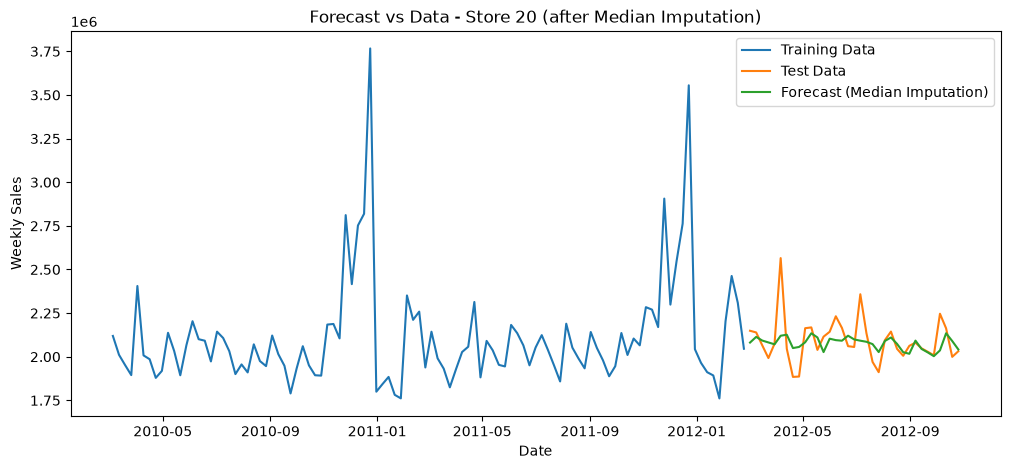

In [88]:
# Use the split from the median imputation cell:
# cleaned training weeks, and the real (unchanged) test weeks
# split_ind_median = int(len(rf_df_current) * 0.75)
#
# train_rf_median_imputed = rf_df_current.iloc[:split_ind_median]
# test_rf_median_imputed = rf_df_current.iloc[split_ind_median:]
train_rf_median_imputed = train_median
test_rf_median_imputed = test_median

x_train_median = train_rf_median_imputed[features]
y_train_median = train_rf_median_imputed['Weekly_Sales']

x_test_median = test_rf_median_imputed[features]
y_test_median = test_rf_median_imputed['Weekly_Sales']

# Predict using the final model trained with best parameters from median imputation
y_pred_median = final_rf_model_median.predict(x_test_median)

# Estimate MAPE
mape_median = np.mean(np.abs((y_test_median - y_pred_median) / y_test_median)) * 100
print("MAPE with Median Imputation:", mape_median)

# plot RF with Median Imputation
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(train_rf_median_imputed['Date'], train_rf_median_imputed['Weekly_Sales'], label='Training Data')
plt.plot(test_rf_median_imputed['Date'], test_rf_median_imputed['Weekly_Sales'], label='Test Data')
plt.plot(test_rf_median_imputed['Date'], y_pred_median, label='Forecast (Median Imputation)')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.title(f'Forecast vs Data - Store {int(best_store)} (after Median Imputation)')
plt.legend()
plt.show()

##Prophet

**What this cell does:** prepares the data and fits a Prophet model.
1. Loads the data and **adds up weekly sales across all 45 stores**, so this model forecasts Walmart's total weekly sales, not Store 20.
2. Prints summary statistics and plots total sales over time.
3. Renames the columns to `ds` (date) and `y` (value), the names Prophet requires.
4. Splits by time (75% train / 25% test).
5. Fits Prophet with yearly and weekly seasonality and predicts the test weeks.

        Date  Weekly_Sales
0 2010-02-05   49750740.50
1 2010-02-12   48336677.63
2 2010-02-19   48276993.78
3 2010-02-26   43968571.13
4 2010-03-05   46871470.30
Basic statictical analisys
                      Date  Weekly_Sales
count                  143  1.430000e+02
mean   2011-06-17 00:00:00  4.711342e+07
min    2010-02-05 00:00:00  3.959985e+07
25%    2010-10-11 12:00:00  4.488059e+07
50%    2011-06-17 00:00:00  4.624390e+07
75%    2012-02-20 12:00:00  4.779202e+07
max    2012-10-26 00:00:00  8.093142e+07
std                    NaN  5.444206e+06


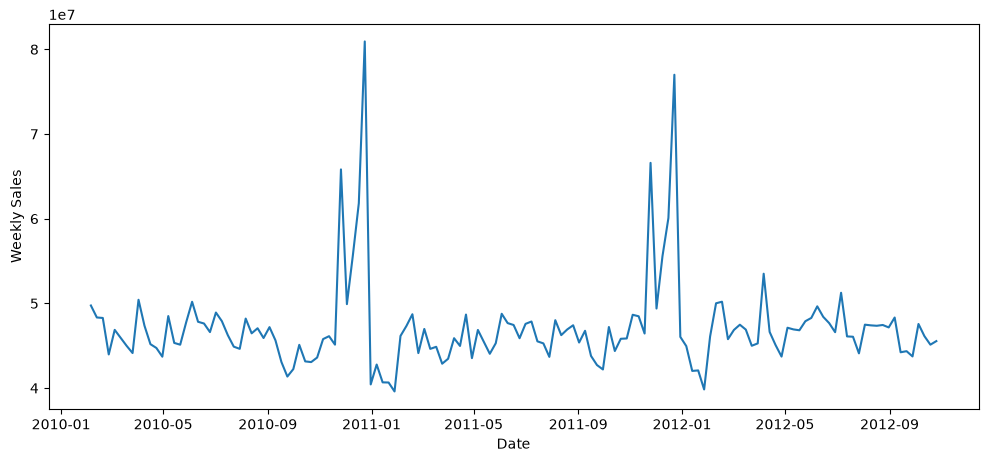

14:18:00 - cmdstanpy - INFO - Chain [1] start processing
14:18:00 - cmdstanpy - INFO - Chain [1] done processing


          ds            y
0 2010-02-05  49750740.50
1 2010-02-12  48336677.63
2 2010-02-19  48276993.78
3 2010-02-26  43968571.13
4 2010-03-05  46871470.30
train
            ds            y
0   2010-02-05  49750740.50
1   2010-02-12  48336677.63
2   2010-02-19  48276993.78
3   2010-02-26  43968571.13
4   2010-03-05  46871470.30
..         ...          ...
102 2012-01-20  42080996.56
103 2012-01-27  39834974.67
104 2012-02-03  46085608.09
105 2012-02-10  50009407.92
106 2012-02-17  50197056.96

[107 rows x 2 columns]
test
            ds            y
107 2012-02-24  45771506.57
108 2012-03-02  46861034.97
109 2012-03-09  47480454.11
110 2012-03-16  46901504.94
111 2012-03-23  44993794.45
112 2012-03-30  45272862.02
113 2012-04-06  53502315.87
114 2012-04-13  46629261.41
115 2012-04-20  45072529.78
116 2012-04-27  43716798.89
117 2012-05-04  47124197.93
118 2012-05-11  46925878.99
119 2012-05-18  46823939.22
120 2012-05-25  47892463.31
121 2012-06-01  48281649.72
122 2012-06-08  49651171.

In [89]:
#from google.colab import drive
#drive.mount('/content/gdrive', force_remount=True)

# !ls "/content/gdrive/MyDrive/Tina AI study"


import pandas as pd
from prophet import Prophet
import io
# Replace 'filename.csv' with your actual file name
df = pd.read_csv('Walmart_Sales.csv', encoding='latin1')
# print(df)
# print(df.columns)
# print(df)
df['Date'] = pd.to_datetime(df['Date'],
                            format = 'mixed',
                            dayfirst = True,
                            errors = 'coerce')
#print(df.sort_values('Date')) #sorted by date from earliest to latest
#print(df.isnull().sum()) #zero outliers
#print(df.info())
#print(df.duplicated().sum()) # no duplicates

sales_by_date = df.groupby('Date')['Weekly_Sales'].sum().reset_index()
sales_by_date = sales_by_date.sort_values('Date')
print(sales_by_date.head())

# EDA
print("Basic statictical analisys")
print(sales_by_date.describe())

# plotting
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(sales_by_date['Date'], sales_by_date['Weekly_Sales'])
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.show()

#datapreparation
prophet_df = sales_by_date.rename(columns={
    'Date' : 'ds',
    'Weekly_Sales' : 'y'
})
print(prophet_df.head())
arima = sales_by_date.set_index('Date')['Weekly_Sales']

#split 80% 20%
split_ind = int(len(sales_by_date) * 0.75)
train = sales_by_date.iloc[:split_ind]
##change the column names
train.columns = ['ds', 'y']
print('train')
print(train)
test = sales_by_date.iloc[split_ind:]
test.columns = ['ds', 'y']
print('test')
print(test)

model_pr = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)
model_pr.fit(train)

future = test[['ds']]
forecast = model_pr.predict(future)
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

**What this cell does:** draws Prophet's built-in forecast chart: black dots are the training data, the blue line is the forecast and the light blue band is the uncertainty range.

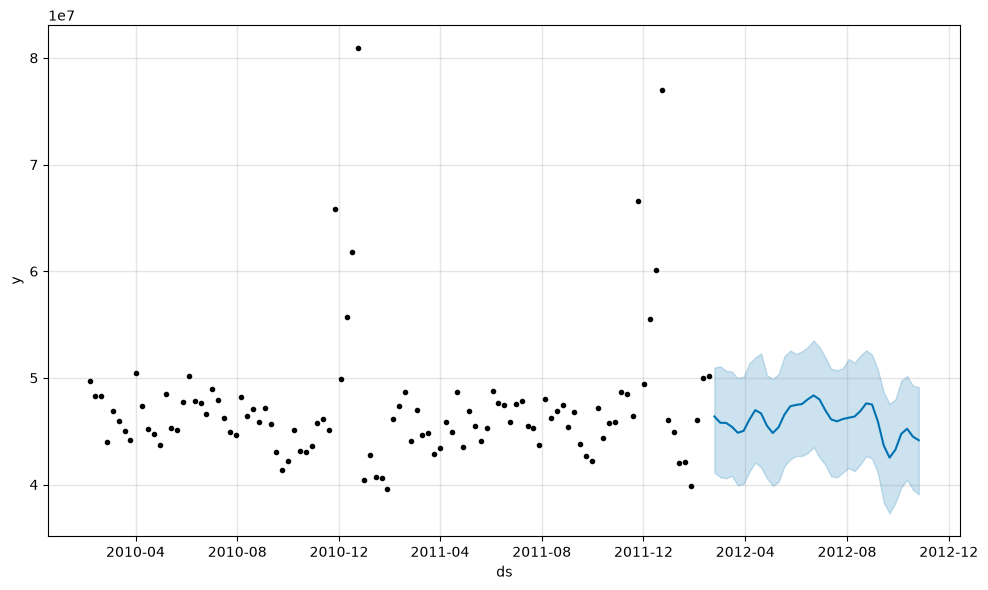

In [90]:
fig1 = model_pr.plot(forecast)

**What this cell does:** draws the same chart as an interactive plotly chart (you can zoom and hover). It replaces Prophet's `plot_plotly`, which fails because of a bug in Prophet 1.5.0.

In [91]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=forecast['ds'], y=forecast['yhat_upper'], line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=forecast['ds'], y=forecast['yhat_lower'], line=dict(width=0), fill='tonexty',
                         fillcolor='rgba(0,114,178,0.2)', name='Uncertainty'))
fig.add_trace(go.Scatter(x=forecast['ds'], y=forecast['yhat'], line=dict(color='#0072B2'), name='Predicted'))
fig.add_trace(go.Scatter(x=model_pr.history['ds'], y=model_pr.history['y'], mode='markers',
                         marker=dict(color='black', size=4), name='Actual'))
fig.update_layout(xaxis_title='Date', yaxis_title='Weekly Sales')
fig.show()

**What this cell does:** measures Prophet's accuracy on the test weeks. It joins the actual and forecast sales by date and calculates MAPE with scikit-learn. This MAPE is a fraction: multiply by 100 to get %.

In [92]:
##evaluation metrics
##performance of the model
#merge actual and predicted data

df_perf = pd.merge(test, forecast[['ds', 'yhat']], on='ds', how='left')
df_perf.columns = ['ds', 'y_actual', 'y_pred']
df_perf

##calculate MAPE using sklearn library
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(df_perf['y_actual'], df_perf['y_pred'])
print(mape)
#

0.027321556146496055


**What this cell does:** runs Prophet's cross-validation: it trains on the first 520 days, forecasts the next 180 days, then moves forward 90 days and repeats, to test the model on several different periods.

In [93]:
##With cross validation
from prophet.diagnostics import cross_validation
df_cv = cross_validation(model_pr, initial='520 days', period='90 days', horizon = '180 days')
df_cv.head()

  0%|          | 0/1 [00:00<?, ?it/s]14:18:00 - cmdstanpy - INFO - Chain [1] start processing
14:18:00 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  7.64it/s]


,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2011-08-26,4.710584e+07,4.244513e+07,5.146516e+07,47416948.45,2011-08-21
1,2011-09-02,4.635070e+07,4.202662e+07,5.083155e+07,45376623.27,2011-08-21
2,2011-09-09,4.425738e+07,3.989274e+07,4.878509e+07,46763227.53,2011-08-21
3,2011-09-16,4.206445e+07,3.755887e+07,4.691957e+07,43793960.08,2011-08-21
4,2011-09-23,4.133309e+07,3.715011e+07,4.565548e+07,42718096.73,2011-08-21


**What this cell does:** calculates error metrics (MSE, RMSE, MAE, MAPE and more) from the cross-validation, grouped by how far ahead the forecast is.

In [94]:
from prophet.diagnostics import performance_metrics
df_p = performance_metrics(df_cv)
df_p.head()

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,12 days,5.228074e+11,7.230542e+05,6.425945e+05,0.014014,0.014014,0.013911,1.0
1,19 days,3.614060e+12,1.901068e+06,1.739964e+06,0.037526,0.037526,0.038150,1.0
2,26 days,4.635257e+12,2.152965e+06,2.117683e+06,0.046539,0.046539,0.047674,1.0
3,33 days,2.454729e+12,1.566758e+06,1.557260e+06,0.035957,0.035957,0.036622,1.0
4,40 days,9.600859e+11,9.798397e+05,7.144671e+05,0.016732,0.016732,0.016998,1.0


**What this cell does:** plots MAPE against how far ahead the forecast is, to show whether the error grows for longer horizons.

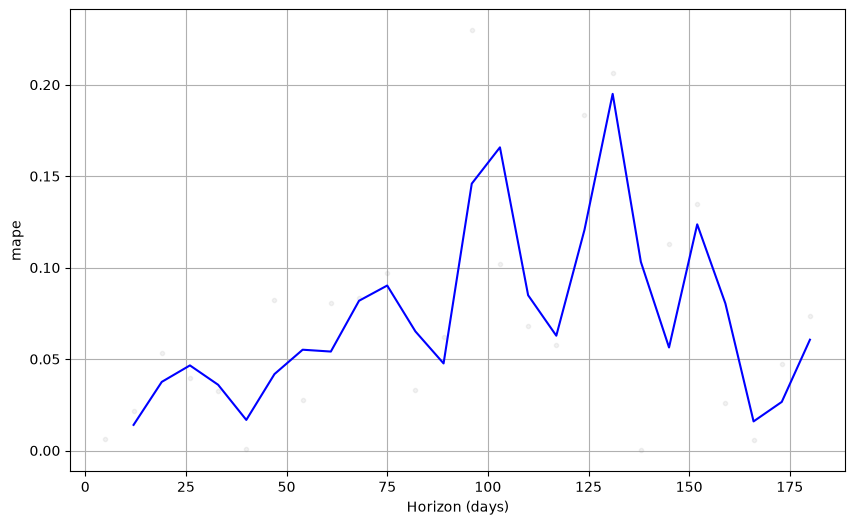

In [95]:
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='mape')


### Hyperparameter Tuning with Cross-Validation

**What this cell does:** tunes Prophet.
1. Tries 16 combinations of `changepoint_prior_scale` (how flexible the trend is) and `seasonality_prior_scale` (how strong the seasonal patterns can be).
2. Scores each with cross-validation and keeps the combination with the lowest MAPE.
3. Trains the final model with those parameters on all the data.

In [96]:
from sklearn.model_selection import ParameterGrid

# Define a grid of hyperparameters to search
param_grid = {
    'changepoint_prior_scale': [0.001, 0.01, 0.1, 0.5],
    'seasonality_prior_scale': [0.01, 0.1, 1.0, 10.0]
}

all_params = list(ParameterGrid(param_grid))

rmses = []  # To store the RMSE for each parameter combination
mapes = [] # To store the MAPE for each parameter combination

print(f'Total models to evaluate: {len(all_params)}')

# Iterate over each parameter combination
for i, params in enumerate(all_params):
    print(f'Evaluating model {i+1}/{len(all_params)} with params: {params}')

    # Create and fit a Prophet model with the current parameters
    model_tune = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        **params # Unpack the dictionary of parameters
    )
    model_tune.fit(train)

    # Perform cross-validation
    df_cv_tune = cross_validation(model_tune, initial='520 days', period='90 days', horizon = '180 days')

    # Calculate performance metrics
    df_p_tune = performance_metrics(df_cv_tune, metrics=['rmse', 'mape'])

    # Get the mean RMSE and MAPE over the horizon (or a specific horizon if desired)
    mean_rmse = df_p_tune['rmse'].mean()
    mean_mape = df_p_tune['mape'].mean()

    rmses.append(mean_rmse)
    mapes.append(mean_mape)

# Find the best parameters based on RMSE or MAPE
# For example, let's find the combination with the lowest MAPE
best_params_idx = mapes.index(min(mapes))
best_params = all_params[best_params_idx]

print(f'\nBest parameters found: {best_params}')
print(f'Lowest MAPE achieved: {min(mapes):.4f}')
print(f'Corresponding RMSE: {rmses[best_params_idx]:.2f}')

# Now, you would retrain your final model using these best parameters
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    **best_params
)
final_model.fit(prophet_df) # Fit on the full dataset or desired training data

print('\nFinal model trained with best parameters!')


14:18:00 - cmdstanpy - INFO - Chain [1] start processing
14:18:00 - cmdstanpy - INFO - Chain [1] done processing
14:18:00 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
14:18:00 - cmdstanpy - INFO - Chain [1] start processing


Total models to evaluate: 16
Evaluating model 1/16 with params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 0.01}


14:18:00 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/1 [00:00<?, ?it/s]14:18:00 - cmdstanpy - INFO - Chain [1] start processing
14:18:01 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  9.88it/s]
14:18:01 - cmdstanpy - INFO - Chain [1] start processing
14:18:01 - cmdstanpy - INFO - Chain [1] done processing
14:18:01 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
14:18:01 - cmdstanpy - INFO - Chain [1] start processing
14:18:01 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 2/16 with params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 0.1}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:01 - cmdstanpy - INFO - Chain [1] start processing
14:18:01 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  9.24it/s]
14:18:01 - cmdstanpy - INFO - Chain [1] start processing
14:18:01 - cmdstanpy - INFO - Chain [1] done processing
14:18:01 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
14:18:01 - cmdstanpy - INFO - Chain [1] start processing


Evaluating model 3/16 with params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 1.0}


14:18:01 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/1 [00:00<?, ?it/s]14:18:01 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  7.26it/s]
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
14:18:02 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 4/16 with params: {'changepoint_prior_scale': 0.001, 'seasonality_prior_scale': 10.0}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  7.54it/s]
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 5/16 with params: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 0.01}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  9.55it/s]
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 6/16 with params: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 0.1}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  8.97it/s]
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 7/16 with params: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 1.0}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00, 10.38it/s]
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 8/16 with params: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 10.0}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00, 10.53it/s]
14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 9/16 with params: {'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 0.01}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:02 - cmdstanpy - INFO - Chain [1] start processing
14:18:02 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  8.00it/s]
14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 10/16 with params: {'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 0.1}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  3.98it/s]
14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 11/16 with params: {'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 1.0}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  6.36it/s]


Evaluating model 12/16 with params: {'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 10.0}


14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/1 [00:00<?, ?it/s]14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  7.21it/s]
14:18:03 - cmdstanpy - INFO - Chain [1] start processing


Evaluating model 13/16 with params: {'changepoint_prior_scale': 0.5, 'seasonality_prior_scale': 0.01}


14:18:03 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/1 [00:00<?, ?it/s]14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  4.50it/s]
14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:03 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 14/16 with params: {'changepoint_prior_scale': 0.5, 'seasonality_prior_scale': 0.1}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:03 - cmdstanpy - INFO - Chain [1] start processing
14:18:04 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  2.68it/s]
14:18:04 - cmdstanpy - INFO - Chain [1] start processing
14:18:04 - cmdstanpy - INFO - Chain [1] done processing


Evaluating model 15/16 with params: {'changepoint_prior_scale': 0.5, 'seasonality_prior_scale': 1.0}


  0%|          | 0/1 [00:00<?, ?it/s]14:18:04 - cmdstanpy - INFO - Chain [1] start processing
14:18:04 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  6.21it/s]


Evaluating model 16/16 with params: {'changepoint_prior_scale': 0.5, 'seasonality_prior_scale': 10.0}


14:18:04 - cmdstanpy - INFO - Chain [1] start processing
14:18:04 - cmdstanpy - INFO - Chain [1] done processing
  0%|          | 0/1 [00:00<?, ?it/s]14:18:04 - cmdstanpy - INFO - Chain [1] start processing
14:18:04 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:00<00:00,  8.53it/s]
14:18:04 - cmdstanpy - INFO - Chain [1] start processing
14:18:04 - cmdstanpy - INFO - Chain [1] done processing



Best parameters found: {'changepoint_prior_scale': 0.1, 'seasonality_prior_scale': 0.01}
Lowest MAPE achieved: 0.0587
Corresponding RMSE: 3915105.40

Final model trained with best parameters!


After running the code above, you would have identified the `best_params` for your model. You can then use this `final_model` with the optimized parameters to make new forecasts or evaluate its performance on a test set (if you still have one separate from the data used for cross-validation).

## Conclusion
Random Forest gave the most accurate forecast for Store 20, with a MAPE of about 3.6–3.8%, meaning it was off by less than 4% on average. ARIMA performed much worse (28%), most likely because it used too much differencing (`d = 2`), even though the ADF test showed the data was already stationary (`d = 0`). Cleaning outliers with KNN or median imputation improved Random Forest only slightly (3.8% → 3.6%), because only 4 values were changed. Prophet reached 2.7%, but it forecast total sales of all 45 stores, so it cannot be compared directly with the other models.
